# 01 · Exploratory analysis

**Milestone 3.** Before training anything, look at the data the model will learn from.
Each section answers one question from the plan, and the notebook ends with the
5 findings that most affect modeling choices.

**Data:** snapshot `2026-10-22-v3`, **train and validation splits only**.
The test split stays locked until Milestone 10, so this notebook never opens it.
Looking at test data now (even just its Team counts) could quietly shape choices
we later "evaluate" on it.

Run from the repo root: `uv run jupyter lab notebooks/01_eda.ipynb`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from pointsman.teams import IN_SCOPE_TEAMS, OUT_OF_SCOPE_TEAMS

# Notebooks run from their own folder; step up to the repo root so data paths work.
if Path.cwd().name == "notebooks":
    %cd ..

SNAPSHOT = Path("data/snapshots/2026-10-22-v3")

train = pd.read_parquet(SNAPSHOT / "split/train.parquet")
val = pd.read_parquet(SNAPSHOT / "split/val.parquet")
train["split"] = "train"
val["split"] = "val"
issues = pd.concat([train, val], ignore_index=True)

print(f"train: {len(train):,}   val: {len(val):,}   total: {len(issues):,}")
issues.head(3)

/Volumes/mySSD/workspace/pointsman
train: 10,261   val: 2,199   total: 12,460


,number,title,prose,code,num_code_blocks,has_stack_trace,created_at,closed_at,state,state_reason,author,team,team_label_id,in_scope,confirmed,routed,team_label_events,duplicate_of,split
0,130048,[Impeller] Discarding stencil attachment on de...,Discovered in https://github.com/flutter/engin...,,0,False,2023-07-06 00:40:50+00:00,NaT,OPEN,NaN,jonahwilliams,team-engine,LA_kwDOAeUeuM8AAAABVCBFPQ,True,True,True,1,NaN,train
1,130051,YearPickerState in calendar_date_picker is usi...,### Steps to reproduce\n\n1. Set a Theme with ...,```\ndayOverlayColor: MaterialStateProperty.re...,4,False,2023-07-06 04:39:45+00:00,2023-07-17 08:08:53+00:00,CLOSED,COMPLETED,CaioT,team-design,LA_kwDOAeUeuM8AAAABVCBE0g,True,False,True,1,NaN,train
2,130055,`didChangeAppLifecycleState` is called with `A...,"### Steps to reproduce\n\nOn iPhone 14 Pro, OS...",```\nflutter: AppLifecycleState: AppLifecycleS...,5,False,2023-07-06 07:57:02+00:00,2023-08-29 06:59:07+00:00,CLOSED,COMPLETED,ashley-arta,team-ios,LA_kwDOAeUeuM8AAAABVCBGHg,True,True,True,2,NaN,train


## 1. How many Issues does each Team get?

Each Team is one **class**: one of the answers the model can give.
When some classes have far more examples than others, that is **class imbalance**.
A lazy model can then score well by mostly guessing the big classes, so plain
accuracy hides how badly it does on small Teams. That is why later milestones
report macro-F1 (every Team counts equally), not only accuracy.

In [2]:
counts = issues["team"].value_counts()
share = (counts / counts.sum() * 100).round(1)
team_table = pd.DataFrame({"issues": counts, "share %": share, "in scope": counts.index.isin(IN_SCOPE_TEAMS)})
team_table

,issues,share %,in scope
team,,,
team-engine,2699,21.7,True
team-framework,1606,12.9,True
team-design,1462,11.7,True
team-ios,1289,10.3,True
team-android,1186,9.5,True
team-web,1140,9.1,True
team-tool,1136,9.1,True
team-ecosystem,862,6.9,True
team-text-input,401,3.2,False


In-scope Issues:     11,380
Out-of-scope Issues: 1,080
Largest / smallest In-scope Team: 3.1x


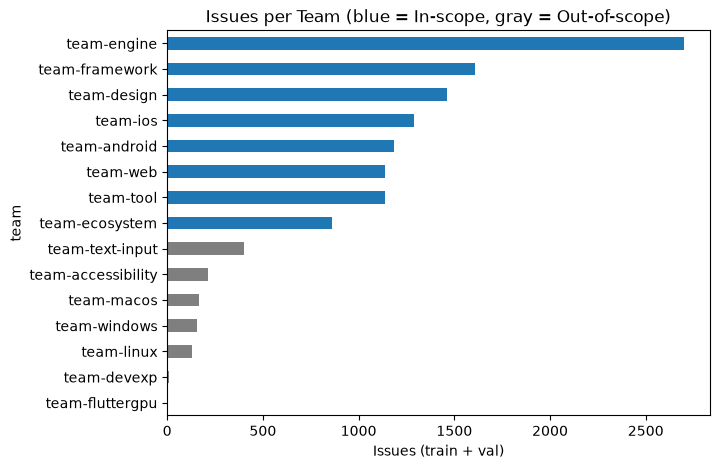

In [3]:
in_scope_counts = counts[counts.index.isin(IN_SCOPE_TEAMS)]
print(f"In-scope Issues:     {in_scope_counts.sum():,}")
print(f"Out-of-scope Issues: {counts[counts.index.isin(OUT_OF_SCOPE_TEAMS)].sum():,}")
print(f"Largest / smallest In-scope Team: {in_scope_counts.max() / in_scope_counts.min():.1f}x")

colors = ["tab:blue" if team in IN_SCOPE_TEAMS else "tab:gray" for team in counts.index]
counts.plot.barh(color=colors, figsize=(7, 5))
plt.gca().invert_yaxis()
plt.xlabel("Issues (train + val)")
plt.title("Issues per Team (blue = In-scope, gray = Out-of-scope)")
plt.show()

## 2. Routed versus Self-labeled, per Team

A **Routed Issue** got its first Team label from someone other than its author:
a triager had to decide. A **Self-labeled Issue** was labeled by its own author,
usually a Flutter engineer filing work for their own Team. Headline results use
Routed Issues only, because routing them is the real task.

If a Team's Issues are mostly Self-labeled, the model sees many training examples
for that Team that look different from what it will meet in real routing.

In [4]:
# routed is True, False, or None (the label history did not say who labeled it).
issues["labeling"] = issues["routed"].map({True: "routed", False: "self-labeled"}).fillna("unknown")

labeling = pd.crosstab(issues["team"], issues["labeling"])
labeling["routed %"] = (labeling["routed"] / labeling.sum(axis=1) * 100).round(1)
labeling = labeling.sort_values("routed %", ascending=False)
labeling

labeling,routed,self-labeled,unknown,routed %
team,,,,
team-devexp,10,0,0,100.0
team-linux,117,12,1,90.0
team-design,1266,188,8,86.6
team-framework,1377,224,5,85.7
team-text-input,333,68,0,83.0
team-windows,128,29,0,81.5
team-ecosystem,674,187,1,78.2
team-macos,127,38,1,76.5
team-accessibility,158,55,0,74.2


Routed share across In-scope Issues: 67.8%


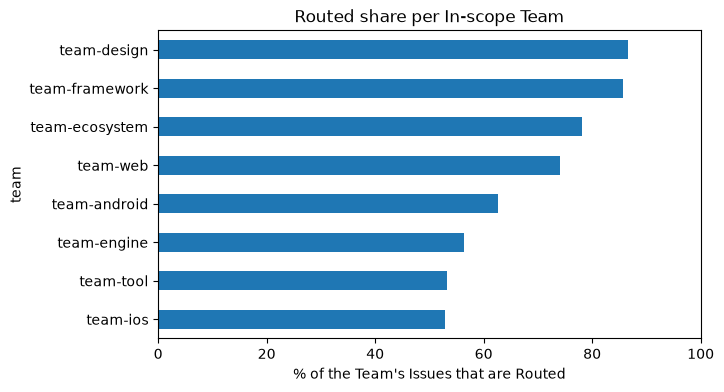

In [5]:
in_scope = issues[issues["in_scope"]]
overall = (in_scope["labeling"] == "routed").mean() * 100
print(f"Routed share across In-scope Issues: {overall:.1f}%")

in_scope_labeling = labeling.loc[labeling.index.isin(IN_SCOPE_TEAMS), "routed %"]
in_scope_labeling.sort_values().plot.barh(figsize=(7, 4))
plt.xlabel("% of the Team's Issues that are Routed")
plt.xlim(0, 100)
plt.title("Routed share per In-scope Team")
plt.show()

## 3. Open and closed Issues across splits

The splits are cut by time: validation is newer than train. Newer Issues have had
less time to be closed, so we expect more of them to be open. That matters if the
label of an open Issue is less settled (it may still move to another Team).

`state_reason` says *why* a closed Issue was closed: `COMPLETED` (fixed or done),
`NOT_PLANNED` (won't fix, not a bug, …) or `DUPLICATE`.

In [6]:
state_mix = pd.crosstab(issues["split"], issues["state"], normalize="index").mul(100).round(1)
state_mix

state,CLOSED,OPEN
split,,
train,66.0,34.0
val,61.6,38.4


In [7]:
closed = issues[issues["state"] == "CLOSED"]
reason_mix = pd.crosstab(closed["split"], closed["state_reason"].fillna("none"), normalize="index").mul(100).round(1)
reason_mix

state_reason,COMPLETED,DUPLICATE,NOT_PLANNED
split,,,
train,90.8,0.9,8.3
val,92.8,3.5,3.6


## 4. How often does an Issue's Team label change?

`team_label_events` counts how many times any Team label was *added* to the Issue.
More than 1 means the Issue **bounced**: someone labeled it one Team, then someone
moved it. Our target is the Team it ended up with.

Bounces are a hint about **label noise**: training labels that are wrong or arguable.
If triagers themselves often change their minds about a Team, the model cannot be
expected to be perfectly right there either, and some "errors" will really be
ambiguous Issues.

In [8]:
issues["bounced"] = issues["team_label_events"] > 1
print(f"Issues that bounced: {issues['bounced'].sum():,} of {len(issues):,} ({issues['bounced'].mean() * 100:.1f}%)")

bounce_by_team = issues.groupby("team")["bounced"].agg(["sum", "mean"])
bounce_by_team.columns = ["bounced", "bounced %"]
bounce_by_team["bounced %"] = (bounce_by_team["bounced %"] * 100).round(1)
bounce_by_team.sort_values("bounced %", ascending=False)

Issues that bounced: 1,767 of 12,460 (14.2%)


,bounced,bounced %
team,,
team-fluttergpu,3,100.0
team-devexp,7,70.0
team-macos,90,54.2
team-windows,76,48.4
team-linux,53,40.8
team-text-input,160,39.9
team-ecosystem,241,28.0
team-design,221,15.1
team-android,167,14.1


In [9]:
# Are Routed Issues more likely to bounce than Self-labeled ones?
(issues.groupby("labeling")["bounced"].mean() * 100).round(1)

labeling
routed          17.3
self-labeled     7.2
unknown         25.0
Name: bounced, dtype: float64

## 5. Monthly volume per Team, with Team Splits marked

The Team Change Log records when each Team label was created. A new Team that
takes over part of older Teams' work is a **Team Split**. If a split shows up as a
visible drop in an older Team's volume, the meaning of that Team changed over time,
which is a form of **concept drift**: the link between Issue text and the right
answer moves, so older training examples teach slightly outdated rules.

The dashed black line is where validation starts.

In [10]:
change_log = pd.read_csv("taxonomy/team_change_log.csv", parse_dates=["date"])
# Teams created inside our data window. The eight In-scope Teams were all created on
# the first day, so they are the starting point, not splits.
first_day_end = issues["created_at"].min().normalize() + pd.Timedelta(days=2)
last_issue = issues["created_at"].max()
created = change_log[change_log["event"] == "team_created"]
new_teams = created[(created["date"] > first_day_end) & (created["date"] <= last_issue)]
new_teams[["date", "team"]]

,date,team
9,2024-03-06 20:10:52+00:00,team-text-input
13,2024-06-05 20:38:46+00:00,team-macos
14,2024-06-05 20:41:55+00:00,team-windows
15,2024-06-05 20:42:49+00:00,team-linux
19,2024-08-14 20:58:35+00:00,team-accessibility
39,2025-05-29 13:19:54+00:00,team-devexp


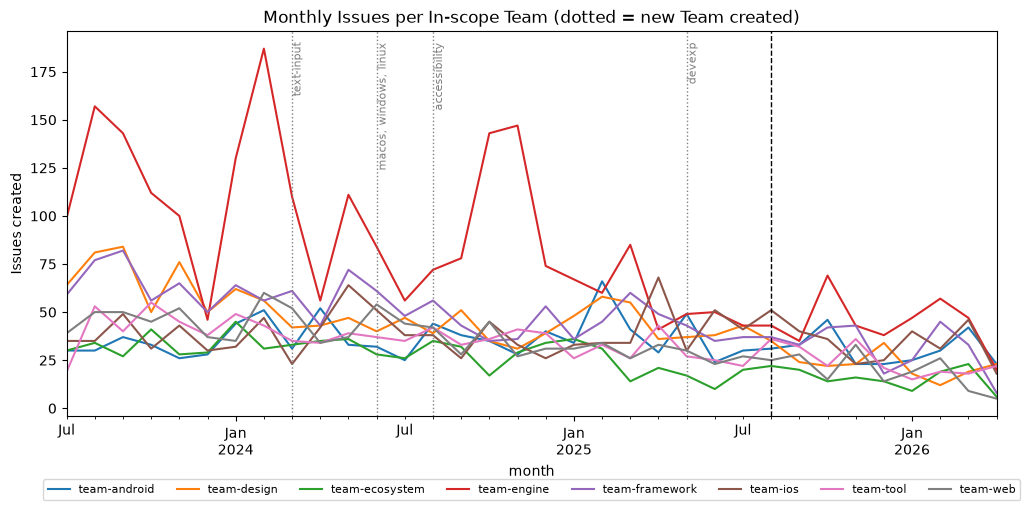

In [11]:
# Count Issues per (month, Team). Drop the timezone first: monthly periods have none.
issues["month"] = issues["created_at"].dt.tz_localize(None).dt.to_period("M")
monthly = pd.crosstab(issues["month"], issues["team"])
monthly_in_scope = monthly[IN_SCOPE_TEAMS]

ax = monthly_in_scope.plot(figsize=(12, 5), linewidth=1.5)
# Teams created in the same month share one marker (macos, windows and linux came the same day).
split_months = new_teams.groupby(new_teams["date"].dt.tz_localize(None).dt.to_period("M"))["team"]
for month, teams in split_months:
    ax.axvline(month, color="gray", linestyle=":", linewidth=1)
    names = ", ".join(team.removeprefix("team-") for team in teams)
    ax.text(month, ax.get_ylim()[1] * 0.97, names, rotation=90, va="top", fontsize=8, color="gray")
ax.axvline(val["created_at"].min().tz_localize(None).to_period("M"), color="black", linestyle="--", linewidth=1)
ax.set_ylabel("Issues created")
ax.set_title("Monthly Issues per In-scope Team (dotted = new Team created)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), fontsize=8, ncol=8)
plt.show()

In [12]:
# team-engine has sharp spikes (e.g. 2024-02, 2024-10). Who filed them, and were they Routed?
engine = issues[issues["team"] == "team-engine"]
for month in ["2024-02", "2024-10"]:
    in_month = engine[engine["month"] == pd.Period(month)]
    top_authors = in_month["author"].value_counts().head(3)
    routed_share = (in_month["labeling"] == "routed").mean() * 100
    print(f"{month}: {len(in_month)} Issues, {routed_share:.0f}% Routed, top 3 authors filed {top_authors.sum() / len(in_month) * 100:.0f}%")
    print("   ", top_authors.to_dict())

2024-02: 187 Issues, 28% Routed, top 3 authors filed 53%
    {'matanlurey': 62, 'chinmaygarde': 21, 'gaaclarke': 17}
2024-10: 143 Issues, 29% Routed, top 3 authors filed 43%
    {'jonahwilliams': 22, 'gaaclarke': 21, 'matanlurey': 18}


In [13]:
# The first and last months are partial: data starts 2023-07-06 and validation ends 2026-04-15.
monthly_in_scope.tail(6)

team,team-android,team-design,team-ecosystem,team-engine,team-framework,team-ios,team-tool,team-web
month,,,,,,,,
2025-11,23,23,16,43,43,23,36,33
2025-12,23,34,14,38,18,25,21,14
2026-01,25,18,9,47,25,40,15,19
2026-02,30,12,19,57,45,31,19,26
2026-03,42,19,23,47,33,46,18,9
2026-04,23,23,6,20,8,18,22,5


## 6. How long are Issues, in tokens?

A transformer model (Milestone 5) does not read words. It reads **tokens**:
pieces of words from a fixed vocabulary (`Flutter` → `Fl` + `utter`). It can only
read a fixed number of tokens per Issue (its **max length**), and cost grows with
that number, so anything past the limit is cut off (**truncated**).

We count tokens with the real tokenizer of `answerdotai/ModernBERT-base`, the model
Milestone 5 fine-tunes, on the same text it will read: title, prose and code.

In [14]:
from tokenizers import Tokenizer

tokenizer = Tokenizer.from_pretrained("answerdotai/ModernBERT-base")


def count_tokens(texts):
    return [len(encoding.ids) for encoding in tokenizer.encode_batch(list(texts))]


issues["title_tokens"] = count_tokens(issues["title"])
issues["prose_tokens"] = count_tokens(issues["prose"])
issues["code_tokens"] = count_tokens(issues["code"])
# Each count includes 2 special tokens ([CLS], [SEP]); keep them once in the total.
issues["total_tokens"] = issues["title_tokens"] + issues["prose_tokens"] + issues["code_tokens"] - 4

issues[["title_tokens", "prose_tokens", "code_tokens", "total_tokens"]].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]).round(0)

,title_tokens,prose_tokens,code_tokens,total_tokens
count,12460.0,12460.0,12460.0,12460.0
mean,19.0,256.0,939.0,1210.0
std,7.0,327.0,2370.0,2407.0
min,4.0,2.0,2.0,4.0
50%,18.0,193.0,174.0,496.0
75%,22.0,311.0,1021.0,1332.0
90%,27.0,453.0,1935.0,2336.0
95%,31.0,632.0,3744.0,4156.0
99%,41.0,1263.0,12926.0,13308.0
max,98.0,14932.0,64869.0,64955.0


In [15]:
for limit in [512, 1024, 2048]:
    over = (issues["total_tokens"] > limit).mean() * 100
    print(f"Issues longer than {limit:>5,} tokens: {over:4.1f}%")

has_code = issues["code_tokens"] > 2
print(f"\nIssues with any code block: {has_code.mean() * 100:.1f}%")
code_share = issues.loc[has_code, "code_tokens"].sum() / issues.loc[has_code, "total_tokens"].sum() * 100
print(f"In those Issues, code is {code_share:.1f}% of all tokens")

Issues longer than   512 tokens: 49.2%
Issues longer than 1,024 tokens: 34.0%
Issues longer than 2,048 tokens: 12.2%

Issues with any code block: 59.9%
In those Issues, code is 84.2% of all tokens


In [16]:
# Milestone 5 will put title and prose first and code last. How often do title + prose alone fit?
issues["title_prose_tokens"] = count_tokens(issues["title"] + "\n" + issues["prose"])
for limit in [512, 1024]:
    fits = (issues["title_prose_tokens"] <= limit).mean() * 100
    print(f"Title + prose fit in {limit:>5,} tokens: {fits:.1f}%")

Title + prose fit in   512 tokens: 91.7%
Title + prose fit in 1,024 tokens: 98.0%


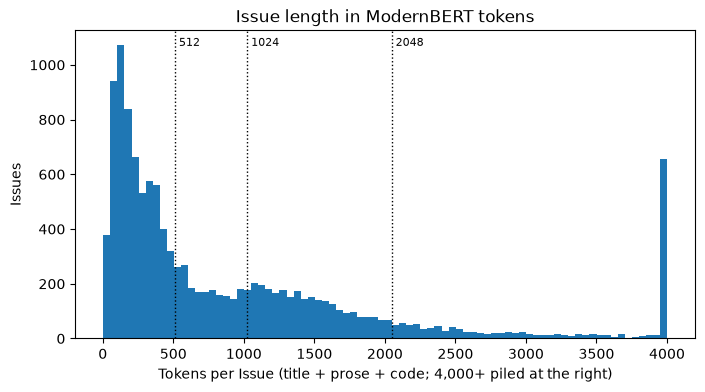

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(issues["total_tokens"].clip(upper=4000), bins=80)
for limit in [512, 1024, 2048]:
    ax.axvline(limit, color="black", linestyle=":", linewidth=1)
    ax.text(limit, ax.get_ylim()[1] * 0.95, f" {limit}", fontsize=8)
ax.set_xlabel("Tokens per Issue (title + prose + code; 4,000+ piled at the right)")
ax.set_ylabel("Issues")
ax.set_title("Issue length in ModernBERT tokens")
plt.show()

In [18]:
# Median length per Team: do some Teams write much longer Issues?
issues.groupby("team")["total_tokens"].median().sort_values(ascending=False)

team
team-text-input       986.0
team-linux            952.0
team-windows          695.0
team-web              660.0
team-framework        659.0
team-design           597.0
team-macos            581.5
team-android          577.0
team-ios              525.0
team-accessibility    457.0
team-tool             401.0
team-ecosystem        379.0
team-engine           371.0
team-devexp           265.0
team-fluttergpu        60.0
Name: total_tokens, dtype: float64

## Findings that most affect modeling

Every number below comes from an output above (snapshot `2026-10-22-v3`, train + val).

1. **Code makes Issues long; the prose is short.** 49.2% of Issues are longer than 512 tokens,
   but in the 59.9% of Issues that contain code, code is 84.2% of the tokens. Title + prose alone
   fit in 512 tokens for 91.7% of Issues.
   *So:* feed the model title, then prose, then code (the Milestone 5 plan), so truncation cuts
   logs, not the description. The Milestone 5 length experiment should ask whether anything past
   512 tokens adds F1. For TF-IDF in Milestone 4, keep code as a separate feature group so long logs
   do not drown the prose.

2. **Class imbalance is moderate.** team-engine has 2,699 of 11,380 In-scope Issues (23.7%),
   3.1x the smallest In-scope Team, team-ecosystem (862).
   *So:* always predicting team-engine would be right 23.7% of the time on these Issues: the floor
   any model must clearly beat. Report macro-F1 next to accuracy. The imbalance is mild enough that
   class weights are worth trying, not heavy resampling.

3. **Self-labeled Issues cluster in a few Teams and a few authors.** 67.8% of In-scope Issues are
   Routed overall, but only 52.8% for team-ios, 53.3% for team-tool and 56.3% for team-engine,
   against 86.6% for team-design. team-engine's spike in 2024-02 was 28% Routed, and its top 3
   authors filed 53% of it.
   *So:* for those Teams, the model may learn a few engineers' writing style instead of what the
   Issue is about. Headline results already use Routed Issues only. In Milestone 4, compare training
   with and without Self-labeled Issues, scored on Routed validation Issues.

4. **Team labels are noisy, especially at Team boundaries.** 14.2% of Issues bounced (got more
   than one Team label): 17.3% of Routed versus 7.2% of Self-labeled, and 28.0% for team-ecosystem.
   Teams created by a Team Split bounce most: team-macos 54.2%, team-windows 48.4%, team-linux 40.8%,
   team-text-input 39.9%.
   *So:* even triagers disagree on about one Issue in seven, so 100% accuracy is not a realistic
   ceiling, and bounced Issues are the first place to look in error analysis. The high bounce rate of
   split-off Teams is the footprint of a Team Split (work moved off older Teams), which Milestone 8
   can use.

5. **About 1 Issue in 11 belongs to a Team the model never predicts.** 1,080 of 12,460 Issues
   (8.7%) are Out-of-scope.
   *So:* a classifier always names one of its eight Teams, so it will confidently mis-route these
   unless the Confidence Cutoff (Milestone 7) sends them to Human review. They are a ready-made test
   for that.